## SPT Trackpy parameter tuning (pipeline-matching)

This notebook is a **visual, single-movie** tool to tune Trackpy particle detection + linking parameters.

### Guaranteed pipeline match
It mirrors the `spt_pipeline.py` command:

- `python spt_pipeline.py track trackpy <input_directory> ...`

and uses the **same detection/linking call signatures and parameter names**:

- **Detection**: `tp.batch(..., diameter=--diam, minmass=--minmass, percentile=--percentile)`
- **Linking**: `tp.link(..., search_range=--range, memory=--memory)`

It also preserves the pipeline’s internal fixed values:

- `separation = 5`
- `noise_size = 1`
- `engine = "numba"`
- `filter_stubs(..., 10)`

### How to use
- Set `movie_path` (or set `input_directory` and choose from the printed list)
- Adjust the **pipeline parameters** (`diam`, `minmass`, `percentile`, `range`, `memory`)
- Re-run the detection + linking cells and inspect overlays/QC plots
- Copy the printed CLI command into your full batch run


In [1]:
from __future__ import annotations

from pathlib import Path
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Core deps used by `spt_pipeline.py track trackpy`
import trackpy as tp
import nd2


def _ver(mod) -> str:
    return getattr(mod, "__version__", "(unknown)")


print("trackpy", _ver(tp))
print("nd2", _ver(nd2))
print("numpy", _ver(np))
print("pandas", _ver(pd))

plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 120


trackpy 0.6.4
nd2 0.10.2
numpy 2.1.3
pandas 2.2.3


In [29]:
# ---- Pipeline-matching parameter space (from `spt_pipeline.py track trackpy`) ----
# These keys intentionally match the argparse names used in the pipeline.

PIPELINE_TRACKPY_ARGS_DEFAULTS = {
    # Defaults below reflect your current tuning session values.
    # They remain within the same parameter space used by `spt_pipeline.py`.
    "mpp": 0.122,
    "fps": 50,
    "diam": 7,
    "range": 5,
    "memory": 0,
    "minmass": 25.0,
    "percentile": 90.0,
}

# These are *fixed* inside `cmd_track_trackpy` (not exposed as CLI args there).
PIPELINE_TRACKPY_CONSTANTS = {
    "separation": 5,
    "noise_size": 1,
    "engine": "numba",
    "filter_stubs_min_frames": 5,
}

# Copy defaults here and edit this dict when tuning.
params = dict(PIPELINE_TRACKPY_ARGS_DEFAULTS)


def show_params() -> None:
    print("Pipeline-matching params (edit `params`):")
    for k in ["diam", "minmass", "percentile", "range", "memory", "mpp", "fps"]:
        print(f"  {k:>10} = {params[k]}")
    print("\nPipeline fixed constants:")
    for k, v in PIPELINE_TRACKPY_CONSTANTS.items():
        print(f"  {k:>22} = {v}")


show_params()


Pipeline-matching params (edit `params`):
        diam = 7
     minmass = 25.0
  percentile = 90.0
       range = 5
      memory = 0
         mpp = 0.122
         fps = 50

Pipeline fixed constants:
              separation = 5
              noise_size = 1
                  engine = numba
  filter_stubs_min_frames = 5


In [30]:
# ---- Choose ONE movie to analyze ----

# Option A: set this directly
movie_path = Path("/Volumes/HoltLab04/20260421 WT HeLa 72-169 WT BiP-HTk JFX650 V3 w beads/V3/NT/DMEM_NT_004.tif")

# Option B: point at a directory and choose from the printed list
input_directory: None | None = None  # e.g. Path("/path/to/images")

# Match pipeline behavior (it skips files whose basename contains "BF_")
skip_bf_files = True


def list_movie_files(root: Path, recursive: bool = True) -> list[Path]:
    root = Path(root)
    patterns = ("*.nd2", "*.tif", "*.tiff")
    files: list[Path] = []
    for pat in patterns:
        files.extend(root.rglob(pat) if recursive else root.glob(pat))
    # de-dup + stable sort
    files = sorted({p.resolve() for p in files})
    if skip_bf_files:
        files = [p for p in files if "BF_" not in p.name]
    return files


if movie_path is None and input_directory is not None:
    candidates = list_movie_files(input_directory, recursive=True)
    print(f"Found {len(candidates)} candidate movies under: {input_directory}")
    for i, p in enumerate(candidates[:50]):
        print(f"[{i:>2}] {p}")
    if len(candidates) > 50:
        print("... (showing first 50)")

    # Pick one, e.g.
    # movie_path = candidates[0]

movie_path


PosixPath('/Volumes/HoltLab04/20260421 WT HeLa 72-169 WT BiP-HTk JFX650 V3 w beads/V3/NT/DMEM_NT_004.tif')

In [31]:
def load_movie_frames(path: Path, *, max_frames: int | None = None) -> list[np.ndarray]:
    """Load frames exactly like `cmd_track_trackpy` in `spt_pipeline.py`.

    Notes:
    - Converts frames to float32
    - If an array has >2 dims, uses the first plane (arr[0]) like the pipeline
    """
    path = Path(path)
    ext = path.suffix.lower()

    frames: list[np.ndarray] = []

    if ext == ".nd2":
        with nd2.ND2File(str(path)) as f:
            data = f.asarray()
        if data.ndim == 4:
            data = data[:, 0, :, :]
        for i in range(data.shape[0]):
            frames.append(data[i].astype(np.float32))
            if max_frames is not None and len(frames) >= max_frames:
                break
        del data

    elif ext in (".tif", ".tiff"):
        import pims
        frames_seq = pims.open(str(path))
        for frame in frames_seq:
            arr = np.array(frame, dtype=np.float32)
            if arr.ndim > 2:
                arr = arr[0]
            frames.append(arr)
            if max_frames is not None and len(frames) >= max_frames:
                break

    else:
        raise ValueError(f"Unsupported file format: {ext}. Expected .nd2, .tif, or .tiff")

    if not frames:
        raise ValueError(f"No frames loaded from: {path}")

    # quick sanity checks
    shapes = {f.shape for f in frames}
    if len(shapes) != 1:
        print(f"[WARN] Not all frames have identical shapes: {sorted(shapes)[:5]} ...")

    return frames


if movie_path is None:
    raise ValueError("Set `movie_path` (or set `input_directory` and pick a candidate).")

# Match pipeline behavior: skip brightfield movies
if "BF_" in movie_path.stem:
    raise ValueError("This file contains 'BF_' in the basename; `spt_pipeline.py track trackpy` skips these.")

frames = load_movie_frames(movie_path)

print(f"Loaded movie: {movie_path.name}")
print(f"Frames: {len(frames)}")
print(f"Frame shape: {frames[0].shape}")
print(f"dtype: {frames[0].dtype}")
print(f"min/max (frame 0): {float(frames[0].min()):.3g} / {float(frames[0].max()):.3g}")


Loaded movie: DMEM_NT_004.tif
Frames: 1000
Frame shape: (512, 323)
dtype: float32
min/max (frame 0): 81 / 152


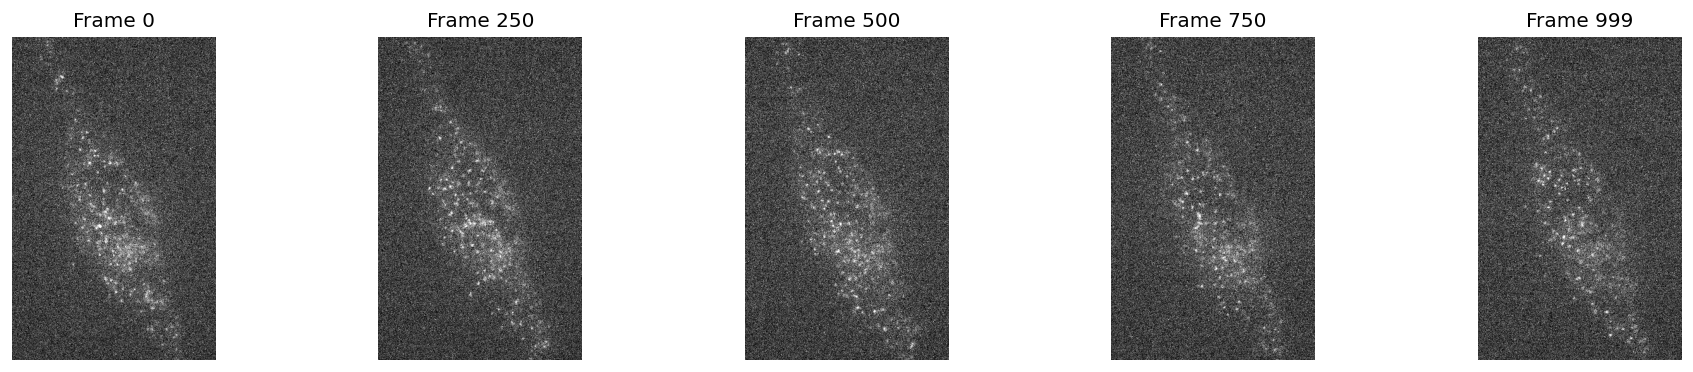

In [32]:
def show_frame(idx: int, *, clip_percentiles=(1, 99.9), cmap="gray", ax=None, title: str | None = None):
    frame = frames[idx]
    vmin, vmax = np.nanpercentile(frame, clip_percentiles)

    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 6))

    ax.imshow(frame, cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_axis_off()
    ax.set_title(title or f"Frame {idx}")
    return ax


# Quick visual sanity check: a few frames across the movie
n = len(frames)
idxs = sorted({0, n // 4, n // 2, (3 * n) // 4, n - 1})

fig, axes = plt.subplots(1, len(idxs), figsize=(3.2 * len(idxs), 3.2))
if len(idxs) == 1:
    axes = [axes]
for ax, idx in zip(axes, idxs):
    show_frame(idx, ax=ax)
plt.tight_layout()


In [33]:
# ---- Choose which frames to analyze ----
# For tuning, it's usually faster to start with a subset, then re-run on the full movie.

analysis_start = 0
analysis_stop = min(len(frames), 200)  # set to len(frames) to match full-movie batch behavior

analysis_frames = frames[analysis_start:analysis_stop]

print(f"Analyzing frames [{analysis_start}:{analysis_stop}] (total {len(analysis_frames)} frames)")

# Frame index (in the ORIGINAL movie) to use for detection overlay previews
viz_frame = analysis_start + min(10, len(analysis_frames) - 1)
print("viz_frame:", viz_frame)


Analyzing frames [0:200] (total 200 frames)
viz_frame: 10


In [34]:
# ---- Particle detection (pipeline-matching) ----

show_params()

particles = tp.batch(
    analysis_frames,
    diameter=params["diam"],
    minmass=params["minmass"],
    separation=PIPELINE_TRACKPY_CONSTANTS["separation"],
    noise_size=PIPELINE_TRACKPY_CONSTANTS["noise_size"],
    percentile=params["percentile"],
    engine=PIPELINE_TRACKPY_CONSTANTS["engine"],
)

particles = particles.copy()
particles["frame"] = particles["frame"].astype(int) + int(analysis_start)

print("Detected features:", len(particles))
print("Columns:", list(particles.columns))
particles.head()


Frame 199: 144 features
Detected features: 28420
Columns: ['y', 'x', 'mass', 'size', 'ecc', 'signal', 'raw_mass', 'ep', 'frame']


,y,x,mass,size,ecc,signal,raw_mass,ep,frame
0,6.824096,55.746988,28.350625,1.437870,0.096494,3.552367,3127.0,0.245978,0
1,12.684109,55.653101,35.250415,1.396285,0.251007,4.782033,3133.0,0.231846,0
2,23.031100,60.251196,28.555569,1.613342,0.401223,3.210794,3112.0,0.290204,0
3,34.730679,46.508197,29.170402,1.592576,0.205831,3.347423,3113.0,0.286766,0
4,62.865546,79.024370,81.294562,1.678585,0.302873,7.377994,3333.0,0.079531,0


viz_frame 10: 142 features


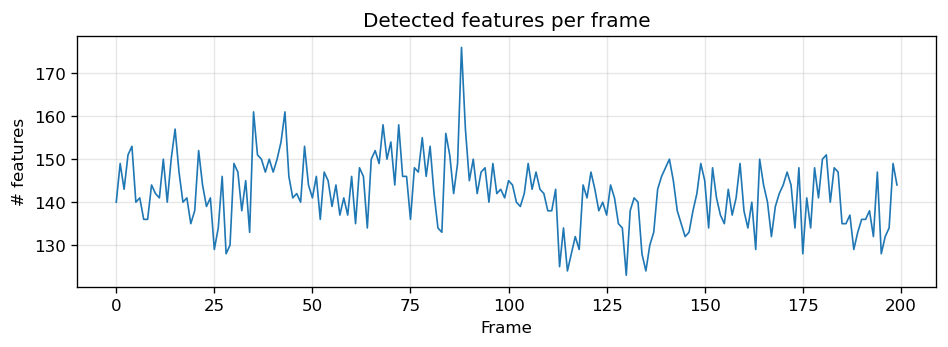

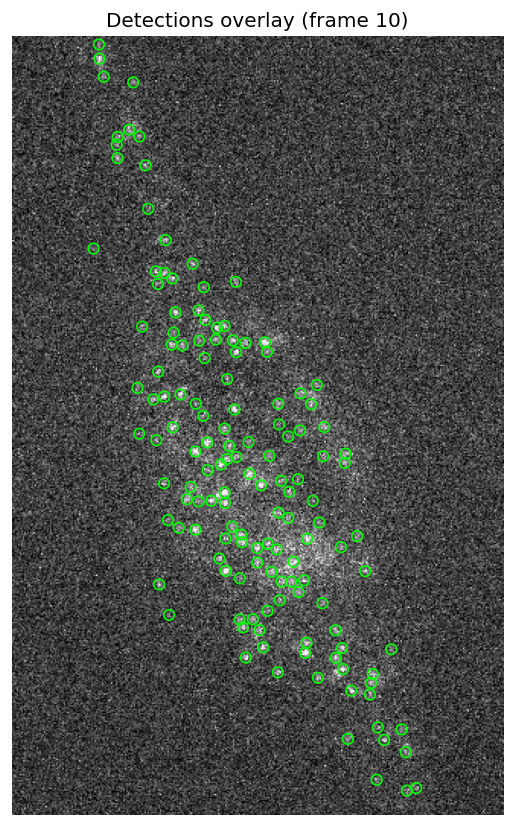

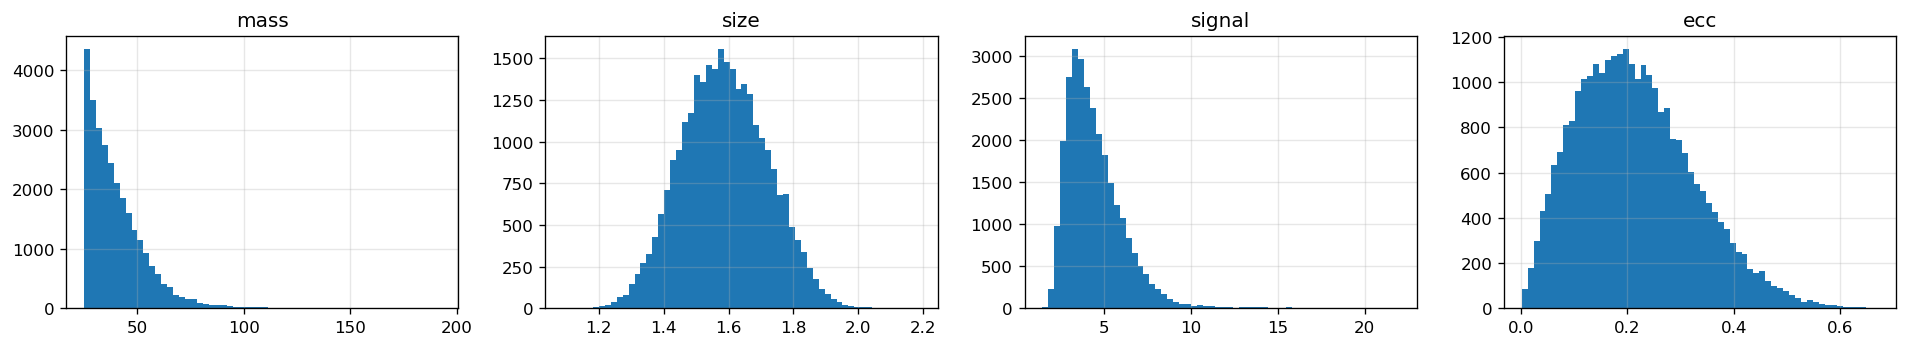

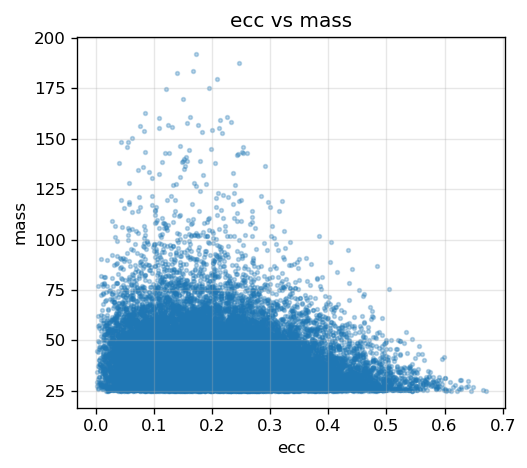

In [35]:
# ---- Visualize detections ----

# Features-per-frame
counts = particles.groupby("frame").size()
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(counts.index.values, counts.values, linewidth=1)
ax.set_xlabel("Frame")
ax.set_ylabel("# features")
ax.set_title("Detected features per frame")
ax.grid(True, alpha=0.3)
plt.tight_layout()

# Detection overlay on a representative frame
f_viz = particles.loc[particles["frame"] == viz_frame]
print(f"viz_frame {viz_frame}: {len(f_viz)} features")

fig, ax = plt.subplots(figsize=(7, 7))
show_frame(viz_frame, ax=ax, title=f"Detections overlay (frame {viz_frame})")
ax.scatter(
    f_viz["x"],
    f_viz["y"],
    s=40,
    facecolors="none",
    edgecolors="lime",
    linewidths=1,
)
plt.tight_layout()

# Simple QC plots (detection)
qc_cols = [c for c in ["mass", "size", "signal", "ecc"] if c in particles.columns]

if not qc_cols:
    print("[WARN] No expected QC columns found in `particles`.")
else:
    fig, axes = plt.subplots(1, len(qc_cols), figsize=(4.0 * len(qc_cols), 3))
    if len(qc_cols) == 1:
        axes = [axes]
    for ax, col in zip(axes, qc_cols):
        ax.hist(particles[col].dropna(), bins=60)
        ax.set_title(col)
        ax.grid(True, alpha=0.3)
    plt.tight_layout()

if "ecc" in particles.columns and "mass" in particles.columns:
    fig, ax = plt.subplots(figsize=(4.5, 4))
    ax.scatter(particles["ecc"], particles["mass"], s=5, alpha=0.3)
    ax.set_xlabel("ecc")
    ax.set_ylabel("mass")
    ax.set_title("ecc vs mass")
    ax.grid(True, alpha=0.3)
    plt.tight_layout()


In [36]:
# ---- Linking (pipeline-matching) ----

if len(particles) == 0:
    raise ValueError("No features detected. Lower `minmass`, adjust `percentile`, or revisit `diam`.")

required_cols = {"frame", "x", "y"}
missing = required_cols - set(particles.columns)
if missing:
    raise ValueError(f"`particles` is missing required columns for linking: {sorted(missing)}")


def flatten_trackpy_df(df: pd.DataFrame) -> pd.DataFrame:
    """Normalize Trackpy output so index levels do not shadow columns.

    Some Trackpy versions return frames where `frame` is both an index level and
    a normal column, which breaks downstream `sort_values(...)` calls in pandas.
    """
    if df is None or len(df) == 0:
        return pd.DataFrame() if df is None else df.reset_index(drop=True)

    out = df.copy()
    if any(name is not None for name in out.index.names):
        out = out.reset_index(drop=True)

    # Keep pipeline-expected dtypes/ordering explicit after normalization.
    if "frame" in out.columns:
        out["frame"] = out["frame"].astype(int)
    return out


# Ensure stable ordering/dtypes for linking
p_link = particles.copy()
p_link["frame"] = p_link["frame"].astype(int)
p_link = p_link.sort_values(["frame"]).reset_index(drop=True)

search_range_requested = int(params["range"])
memory = int(params["memory"])

try:
    from trackpy.linking.utils import SubnetOversizeException
except Exception:
    SubnetOversizeException = None


def try_link_with_range(df: pd.DataFrame, search_range: int, memory: int) -> pd.DataFrame:
    # Pipeline-equivalent call.
    # Use positional arg for search_range for robustness across Trackpy versions.
    linked = tp.link(df, search_range, memory=memory)
    return flatten_trackpy_df(linked)


tracks = None
used_search_range = search_range_requested

for candidate_range in range(search_range_requested, 0, -1):
    try:
        tracks = try_link_with_range(p_link, candidate_range, memory)
        used_search_range = candidate_range
        break
    except Exception as e:
        is_subnet_oversize = (
            (SubnetOversizeException is not None and isinstance(e, SubnetOversizeException))
            or ("SubnetOversizeException" in type(e).__name__)
            or ("search_range (aka maxdisp) too large" in str(e))
        )
        if is_subnet_oversize and candidate_range > 1:
            print(
                f"Linking failed at range={candidate_range} with subnet oversize; retrying range={candidate_range - 1}"
            )
            continue

        import traceback

        print("Linking FAILED.")
        print(f"{type(e).__name__}: {e}")
        print(traceback.format_exc())
        tracks = pd.DataFrame()
        break

if tracks is None:
    tracks = pd.DataFrame()

if tracks.empty:
    filtered_tracks = pd.DataFrame()
    print("No linked tracks were produced.")
    print("Suggestions:")
    print("- Reduce `params['range']`")
    print("- Increase `params['minmass']` and/or `params['percentile']`")
    print("- Reduce movie crowding by testing a quieter segment first")
else:
    if used_search_range != search_range_requested:
        print(
            f"Requested range={search_range_requested} caused subnet oversize. "
            f"Using range={used_search_range} instead."
        )
        params["range"] = used_search_range

    filtered_tracks = tp.filter_stubs(tracks, PIPELINE_TRACKPY_CONSTANTS["filter_stubs_min_frames"])
    filtered_tracks = flatten_trackpy_df(filtered_tracks)

    print("Linked rows:", len(tracks))
    print("Linked particles:", tracks["particle"].nunique() if len(tracks) else 0)
    print("After filter_stubs:")
    print("  rows:", len(filtered_tracks))
    print("  particles:", filtered_tracks["particle"].nunique() if len(filtered_tracks) else 0)

filtered_tracks.head()


Frame 199: 144 trajectories present.
Linked rows: 28420
Linked particles: 7448
After filter_stubs:
  rows: 18868
  particles: 1273


,y,x,mass,size,ecc,signal,raw_mass,ep,frame,particle
0,6.824096,55.746988,28.350625,1.437870,0.096494,3.552367,3127.0,0.245978,0,0
1,130.556589,99.817054,44.063019,1.568587,0.154964,5.396866,3168.0,0.173647,0,3
2,150.581019,118.251157,59.023951,1.599696,0.199343,6.284958,3220.0,0.126478,0,5
3,159.090011,111.738749,62.234745,1.486123,0.168116,7.377994,3253.0,0.107880,0,7
4,178.115075,107.535098,59.365525,1.550827,0.087709,6.694846,3241.0,0.113974,0,10


Plotting a random subset of 300 / 1273 tracks


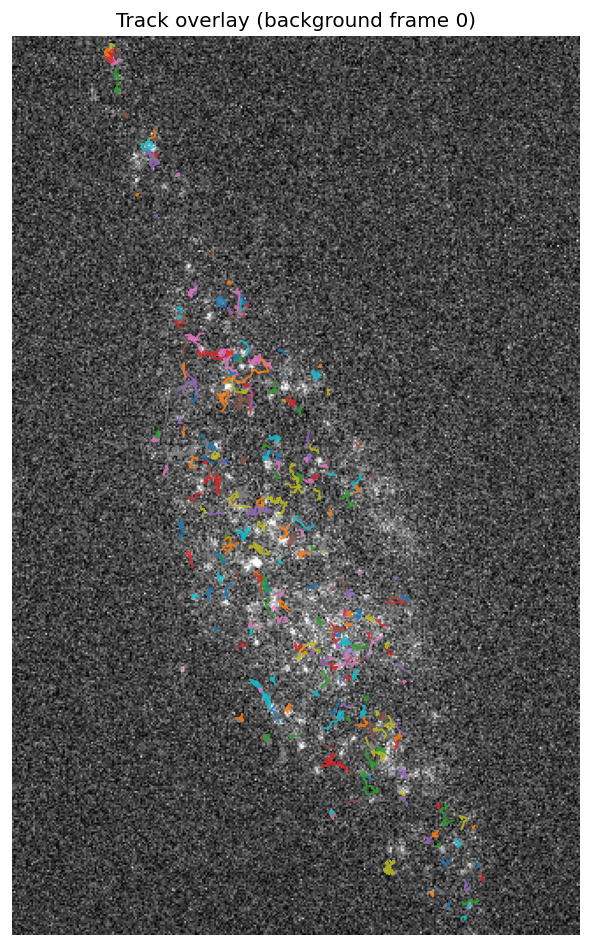

In [37]:
# ---- Visualize tracks ----

if filtered_tracks.empty:
    print("No tracks to plot (linking failed, or all tracks were filtered out).")
else:
    tracks_to_plot = filtered_tracks.reset_index(drop=True).copy()
    overlay_frame = analysis_start

    max_tracks_to_plot = 300  # keep notebook responsive; set to None to plot all

    particle_ids = tracks_to_plot["particle"].unique()
    if max_tracks_to_plot is not None and len(particle_ids) > max_tracks_to_plot:
        rng = np.random.default_rng(0)
        particle_ids = rng.choice(particle_ids, size=max_tracks_to_plot, replace=False)
        tracks_to_plot = tracks_to_plot[tracks_to_plot["particle"].isin(particle_ids)]
        print(
            f"Plotting a random subset of {max_tracks_to_plot} / {filtered_tracks['particle'].nunique()} tracks"
        )
    else:
        print(f"Plotting all {filtered_tracks['particle'].nunique()} tracks")

    fig, ax = plt.subplots(figsize=(8, 8))
    show_frame(overlay_frame, ax=ax, title=f"Track overlay (background frame {overlay_frame})")
    for _, g in tracks_to_plot.groupby("particle"):
        g = g.reset_index(drop=True).sort_values("frame")
        ax.plot(g["x"], g["y"], linewidth=1.2, alpha=0.85)
    plt.tight_layout()


Track length (frames):
  n_tracks: 1273
  min/median/max: 5 9 200
Step size (px) percentiles:
  p50=1.07, p90=2.65, p95=3.35, p99=4.5
  current search_range (--range) = 5
  fraction steps > search_range: 0.000%


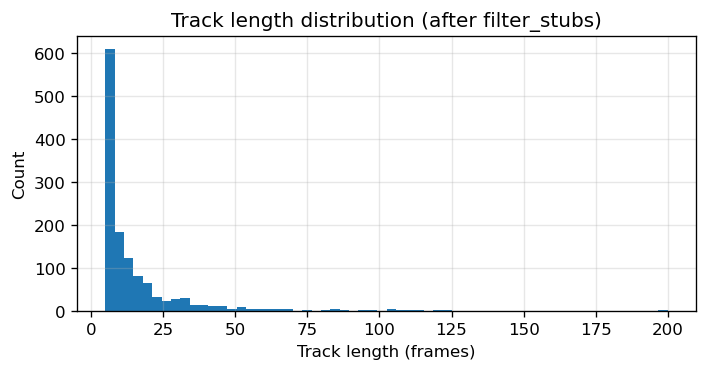

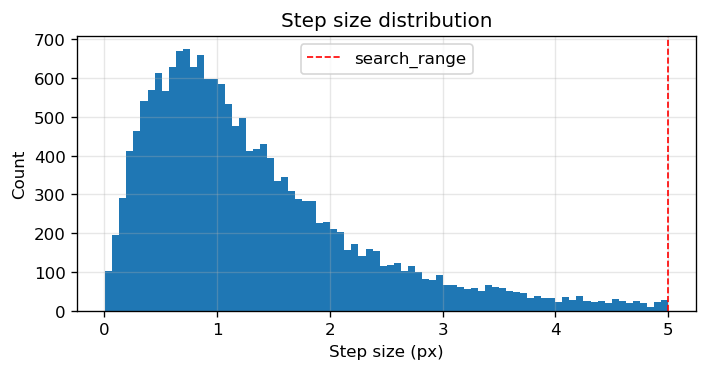

In [38]:
# ---- QC for linking ----

if filtered_tracks.empty:
    print("No tracks available for QC (linking failed, or all tracks were filtered out).")
else:
    ft = filtered_tracks.reset_index(drop=True).copy()

    lengths = ft.groupby("particle")["frame"].count().astype(int)
    print("Track length (frames):")
    print("  n_tracks:", len(lengths))
    print("  min/median/max:", int(lengths.min()), int(lengths.median()), int(lengths.max()))

    fig, ax = plt.subplots(figsize=(6, 3.2))
    ax.hist(lengths, bins=min(60, max(10, int(lengths.max()))))
    ax.set_xlabel("Track length (frames)")
    ax.set_ylabel("Count")
    ax.set_title("Track length distribution (after filter_stubs)")
    ax.grid(True, alpha=0.3)
    plt.tight_layout()

    ft = ft.sort_values(["particle", "frame"]).copy()
    ft["dx"] = ft.groupby("particle")["x"].diff()
    ft["dy"] = ft.groupby("particle")["y"].diff()
    ft["step_px"] = np.sqrt(ft["dx"] ** 2 + ft["dy"] ** 2)
    steps = ft["step_px"].dropna()

    if len(steps) == 0:
        print("No step sizes available after filtering (all tracks are single-frame after differencing).")
    else:
        q50, q90, q95, q99 = np.percentile(steps, [50, 90, 95, 99])
        print("Step size (px) percentiles:")
        print(f"  p50={q50:.3g}, p90={q90:.3g}, p95={q95:.3g}, p99={q99:.3g}")
        print(f"  current search_range (--range) = {params['range']}")
        print(f"  fraction steps > search_range: {float(np.mean(steps > params['range'])):.3%}")

        fig, ax = plt.subplots(figsize=(6, 3.2))
        ax.hist(steps, bins=80)
        ax.axvline(params["range"], color="red", linestyle="--", linewidth=1, label="search_range")
        ax.set_xlabel("Step size (px)")
        ax.set_ylabel("Count")
        ax.set_title("Step size distribution")
        ax.grid(True, alpha=0.3)
        ax.legend()
        plt.tight_layout()


In [39]:
# ---- Export tuned params for the full pipeline ----

batch_input_directory = input_directory if input_directory is not None else movie_path.parent

cmd = (
    f"python spt_pipeline.py track trackpy {batch_input_directory} "
    f"--diam {params['diam']} "
    f"--minmass {params['minmass']} "
    f"--percentile {params['percentile']} "
    f"--range {params['range']} "
    f"--memory {params['memory']}"
)

print("Run the full batch pipeline with:")
print(cmd)

# Machine-readable block (keys match pipeline argparse names)
export_block = {k: params[k] for k in ["diam", "minmass", "percentile", "range", "memory", "mpp", "fps"]}
print("\nParameter block:")
print(pd.Series(export_block))

print("\nPipeline fixed constants (for reference):")
print(pd.Series(PIPELINE_TRACKPY_CONSTANTS))


Run the full batch pipeline with:
python spt_pipeline.py track trackpy /Volumes/HoltLab04/20260421 WT HeLa 72-169 WT BiP-HTk JFX650 V3 w beads/V3/NT --diam 7 --minmass 25.0 --percentile 90.0 --range 5 --memory 0

Parameter block:
diam           7.000
minmass       25.000
percentile    90.000
range          5.000
memory         0.000
mpp            0.122
fps           50.000
dtype: float64

Pipeline fixed constants (for reference):
separation                     5
noise_size                     1
engine                     numba
filter_stubs_min_frames        5
dtype: object
